<a href="https://colab.research.google.com/github/AhmadKevin000/machineLearning/blob/main/week12_tugasPrak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum — Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (60000, 28, 28) | X_test: (10000, 28, 28)


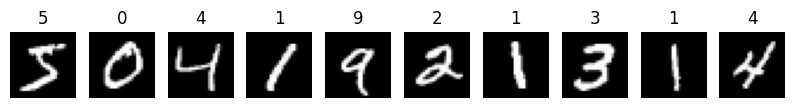

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train_raw), (X_test, y_test_raw) = mnist.load_data()

# Normalisasi data (0-255 -> 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label (simpan label asli untuk confusion matrix)
y_train = to_categorical(y_train_raw, 10)
y_test = to_categorical(y_test_raw, 10)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(y_train_raw[i]); plt.axis('off')
plt.show()

## 2-5. Model dasar: 2 hidden layer (128-64, ReLU)

Model dasar sesuai template soal: **Flatten → Dense(128) → Dense(64) → Dense(10, softmax)**.

In [2]:
def build_and_train(hidden_layers, activation="relu", epochs=10, label=""):
    """Bangun, latih, dan evaluasi model MNIST. Mengembalikan loss, akurasi, waktu, dan history."""
    tf.keras.utils.set_random_seed(42)
    layers = [Flatten(input_shape=(28, 28))]
    for n in hidden_layers:
        layers.append(Dense(n, activation=activation))
    layers.append(Dense(10, activation='softmax'))
    m = Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    start = time.time()
    h = m.fit(X_train, y_train, epochs=epochs, batch_size=128,
              validation_split=0.1, verbose=0)
    elapsed = time.time() - start

    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    print(f"{label:35s} -> akurasi: {acc:.4f}, loss: {loss:.4f}, waktu: {elapsed:.1f}s")
    return loss, acc, elapsed, h, m

# Model dasar
loss0, acc0, t0, h0, model0 = build_and_train([128, 64], "relu", epochs=10,
                                              label="Dasar 2 hidden (128-64, ReLU)")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Dasar 2 hidden (128-64, ReLU)       -> akurasi: 0.9707, loss: 0.1036, waktu: 26.9s


## Eksperimen 1 — Ubah jumlah neuron hidden layer (256 dan 128)

In [3]:
loss1, acc1, t1, h1, _ = build_and_train([256, 128], "relu", epochs=10,
                                          label="Neuron lebih besar (256-128, ReLU)")

Neuron lebih besar (256-128, ReLU)  -> akurasi: 0.9740, loss: 0.1030, waktu: 32.8s


## Eksperimen 2 — Tambah satu hidden layer lagi (3 hidden layer)

In [4]:
loss2, acc2, t2, h2, _ = build_and_train([256, 128, 64], "relu", epochs=10,
                                          label="3 hidden layer (256-128-64, ReLU)")

3 hidden layer (256-128-64, ReLU)   -> akurasi: 0.9706, loss: 0.1101, waktu: 32.0s


## Eksperimen 3 — Sigmoid vs ReLU

Arsitektur sama (256-128), hanya aktivasi hidden layer yang diubah. Output layer tetap **softmax** karena klasifikasi 10 kelas.

In [5]:
loss3, acc3, t3, h3, _ = build_and_train([256, 128], "sigmoid", epochs=10,
                                          label="Aktivasi Sigmoid (256-128)")

Aktivasi Sigmoid (256-128)          -> akurasi: 0.9738, loss: 0.0819, waktu: 31.0s


## Perbandingan hasil

In [6]:
hasil = pd.DataFrame({
    "Konfigurasi": [
        "2 hidden (128-64, ReLU)  [dasar]",
        "2 hidden (256-128, ReLU)",
        "3 hidden (256-128-64, ReLU)",
        "2 hidden (256-128, Sigmoid)",
    ],
    "Akurasi Uji": [acc0, acc1, acc2, acc3],
    "Loss Uji": [loss0, loss1, loss2, loss3],
    "Waktu Latih (s)": [t0, t1, t2, t3],
})
hasil

,Konfigurasi,Akurasi Uji,Loss Uji,Waktu Latih (s)
0,"2 hidden (128-64, ReLU) [dasar]",0.9707,0.103627,26.929406
1,"2 hidden (256-128, ReLU)",0.9740,0.103003,32.766422
2,"3 hidden (256-128-64, ReLU)",0.9706,0.110094,32.004076
3,"2 hidden (256-128, Sigmoid)",0.9738,0.081926,31.017890


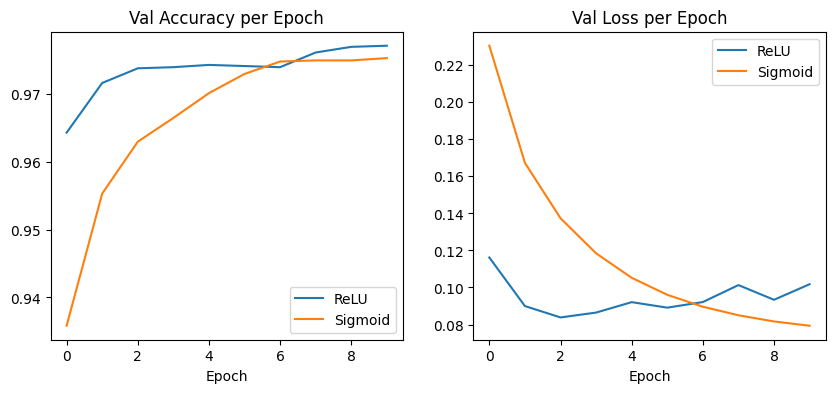

In [7]:
# Kurva pembelajaran: ReLU vs Sigmoid
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h1.history['val_accuracy'], label='ReLU')
plt.plot(h3.history['val_accuracy'], label='Sigmoid')
plt.title('Val Accuracy per Epoch'); plt.xlabel('Epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(h1.history['val_loss'], label='ReLU')
plt.plot(h3.history['val_loss'], label='Sigmoid')
plt.title('Val Loss per Epoch'); plt.xlabel('Epoch'); plt.legend()
plt.show()

## Analisis Prediksi Model Dasar (Confusion Matrix)

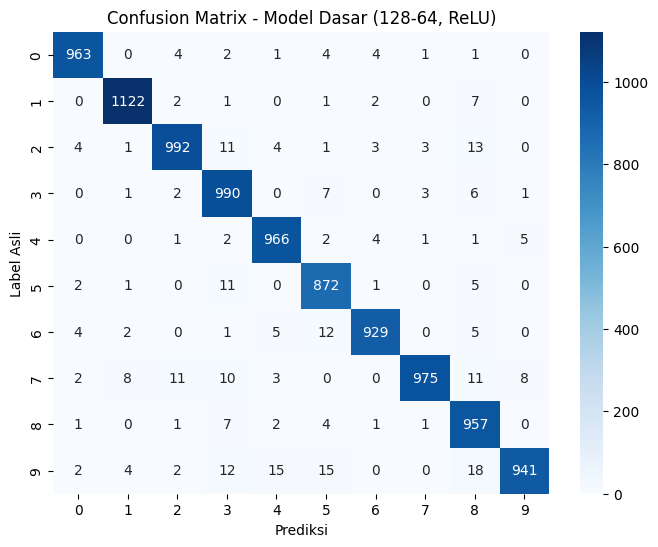

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

pred = np.argmax(model0.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test_raw, pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prediksi'); plt.ylabel('Label Asli'); plt.title('Confusion Matrix - Model Dasar (128-64, ReLU)')
plt.show()

### Analisis / Kesimpulan

**Jumlah neuron:**
- Menambah neuron (128-64 → 256-128) memberi kapasitas lebih sehingga akurasi umumnya sedikit naik, dengan konsekuensi waktu latih lebih lama (lebih banyak parameter).
- Peningkatan akurasinya kecil karena MNIST adalah dataset yang relatif mudah; model dasar saja sudah mencapai ~97-98%.

**Jumlah hidden layer:**
- Menambah 1 hidden layer (3 hidden layer) tidak memberikan peningkatan signifikan untuk MLP pada MNIST — justru waktu latih bertambah. Untuk data gambar, CNN jauh lebih efektif daripada menumpuk Dense layer.

**Sigmoid vs ReLU:**
- **ReLU** konvergen jauh lebih cepat — dalam beberapa epoch pertama akurasinya sudah tinggi, karena tidak mengalami *vanishing gradient* (gradien Sigmoid maksimal hanya 0.25).
- **Sigmoid** lebih lambat konvergen dan loss akhirnya lebih tinggi; dalam 10 epoch akurasinya di bawah ReLU.
- Kesimpulan: **ReLU + softmax** adalah pilihan standar yang tepat untuk klasifikasi MNIST dengan MLP.

**Waktu pelatihan:** sebanding dengan jumlah parameter — semakin besar/t dalam arsitektur, semakin lama latihannya.